In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [ ]:
conn = sqlite3.connect('customer_churn.db.db')
sql_query = """
         SELECT name
         FROM sqlite_master
         WHERE type = 'table'
"""
tables = pd.read_sql(sql_query, conn)

for table_name in tables['name']:
  df = pd.read_sql(f"SELECT * FROM {table_name}", conn)
  globals()[f"df_{table_name}"] = df
  print(f"created dataframe: df_{table_name}")

conn.close()

In [ ]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [ ]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     object
 1   name        21 non-null     object
 2   country     18 non-null     object
 3   state       21 non-null     object
 4   gender      21 non-null     object
 5   dob         21 non-null     object
 6   interests   4 non-null      object
 7   pincode     0 non-null      object
dtypes: object(8)
memory usage: 1.4+ KB


In [ ]:
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,None,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,None,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,None,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,None,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,None,None


In [ ]:
#RENAME COLUMN


df_db_customer.rename(columns={'name' : 'customer'}, inplace=True)

In [ ]:
#Drop column



df_db_customer.drop(columns=['interests','pincode'], inplace=True)

In [ ]:
#Change Datatype
df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [ ]:
df_db_customer.tail()

,customerid,customer,country,state,gender,dob
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06


In [ ]:
#data standerdization

df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'}, inplace=True)

/tmp/ipykernel_3876/1141451779.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'}, inplace=True)


In [ ]:
#Missing values update
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer,country,state,gender,dob
5,0013-MHZWF,durga,None,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,None,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,None,Telangana,Female,2004-12-01


In [ ]:
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state']).map(state_country_mapping)

In [ ]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [ ]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     object 
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     object 
 5   contract_type            21 non-null     object 
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      object 
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 1.9+ KB


In [ ]:
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']
df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     object        
 1   subscription_start_date  21 non-null     datetime64[ns]
 2   subscription_type        21 non-null     object        
 3   renewal_date             21 non-null     datetime64[ns]
 4   plan_type                21 non-null     object        
 5   contract_type            21 non-null     object        
 6   cancellation_date        6 non-null      datetime64[ns]
 7   cancellation_reason      6 non-null      object        
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 1.9+ KB


In [ ]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,None
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,None


In [ ]:
df_db_support.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      object
 1   complaint_date  9 non-null      object
 2   escalations     9 non-null      object
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      object
dtypes: int64(1), object(5)
memory usage: 564.0+ bytes


In [ ]:
df_db_support.drop(columns=['col_1','comment'], inplace=True)

In [ ]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

In [ ]:
df_db_subscription['churn_flag']= np.where(df_db_subscription['cancellation_date'].notna(),1, 0)

In [ ]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [ ]:
df = (df_db_subscription
                .merge(df_db_support, on='customerid', how='left')
                .merge(df_db_customer, on='customerid', how='left'))

In [ ]:
df_db_subscription['customerid'].unique().shape

(21,)

In [ ]:
df_db_support['customerid'].unique().shape

(7,)

In [ ]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30


In [ ]:
df_db_support['complaint_count']=df_db_support.groupby('customerid')['customerid'].transform('count')

In [ ]:

df_db_support=df_db_support.sort_values('complaint_count').drop_duplicates('customerid', keep = 'last')

In [ ]:
df=(df_db_subscription
                  .merge(df_db_customer, on='customerid', how='left')
                  .merge(df_db_support, on='customerid', how='left'))

In [ ]:
df.shape

(21, 21)

In [ ]:
df.to_csv('exported_churn_data.csv', index=False)

In [ ]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [ ]:
churn_rate=df['churn_flag'].mean()*100
print("churn rate =", round(churn_rate, 2), "%")

churn rate = 28.57 %


In [ ]:
retention_rate=100-churn_rate
print("Retention rate =", round(retention_rate, 2), "%")

Retention rate = 71.43 %


In [ ]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [ ]:
churn_by_plan = df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name = ('churn_rate_pct'))
print( churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [ ]:
arpu = df['monthly_charges'].mean()
print("ARPU =", round(arpu,2) )

ARPU = 18.85


In [ ]:
today = pd.Timestamp.today()

# Convert date columns in the merged df to datetime to prevent TypeError
df['cancellation_date'] = pd.to_datetime(df['cancellation_date'])
df['subscription_start_date'] = pd.to_datetime(df['subscription_start_date'])

df['tenure_day'] = np.where(
 df['cancellation_date'].notna(),
 (df['cancellation_date'] - df['subscription_start_date']).dt.days,
 (today - df['subscription_start_date']).dt.days
)
avg_tenure = df['tenure_day'].mean()
print("Average Tenure(Days) =", round(avg_tenure, 0))

Average Tenure(Days) = 1562.0


In [ ]:
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at risk RS (k) =" , revenue_at_risk)

Revenue at risk RS (k) = 73.94


In [ ]:
escaltion_rate = (df['escalations']=='Y').mean()*100
print("Escalations Rate =",round(escaltion_rate,2),'%')

Escalations Rate = 14.29 %


In [ ]:
df.shape

(21, 22)

In [ ]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_day'],
      dtype='object')

In [ ]:
ave_cimplaint = df['complaint_count'].sum() / df['customerid'].nunique()
print('Average Complaints =', round(ave_cimplaint, 2))

Average Complaints = 0.43


In [ ]:
# Rebuild df from original dataframes to restore the original 'escalations' values
df = (df_db_subscription
      .merge(df_db_customer, on='customerid', how='left')
      .merge(df_db_support, on='customerid', how='left'))

# Map 'Y' to 1 and everything else (N and NaN from no complaints) to 0
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0)

# Compute correlation
corr_df = df[['escalations', 'churn_flag']].dropna()
correlation = corr_df['escalations'].corr(df['churn_flag'])
print("correlation b/w escalations and churn =", round(correlation, 2))

correlation b/w escalations and churn = 0.65


In [ ]:
conditions =[

            (df['churn_score'] <50),
            (df['churn_score'] >=50) & (df['churn_score'] <70),
            (df['churn_score'] >-70)

             ]
choices = ['low', 'med', 'high']
df['churn_risk'] =np.select(conditions, choices, default ='unknown')


In [ ]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,churn_risk
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,keshav,NaN,Maharashtra,Male,1982-04-12,NaT,0,NaN,NaN,low
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,NaN,Karnataka,Male,1995-11-23,2024-08-28,0,60.0,2.0,high
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,lalita,NaN,Delhi,Female,1978-02-15,NaT,0,NaN,NaN,low
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,mohan,NaN,Nagaland,Male,2001-08-30,NaT,0,NaN,NaN,low
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,mira,NaN,Delhi,Female,1990-05-05,2024-01-20,1,20.0,1.0,high


In [ ]:
df_visuals = df.copy()

In [ ]:
df_visuals.shape

(21, 22)

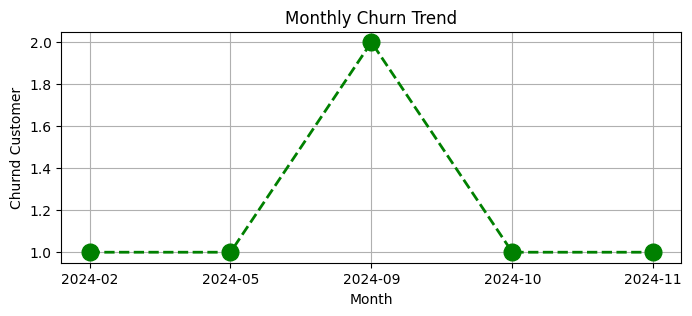

In [ ]:
from matplotlib.lines import lineStyles

# Convert cancellation_date to datetime to enable the .dt accessor
df_visuals['cancellation_date'] = pd.to_datetime(df_visuals['cancellation_date'])

df_visuals['cancellation_month'] = df_visuals['cancellation_date'].dt.to_period('M')
churn_trend = df_visuals[df_visuals['churn_flag']==1].groupby('cancellation_month').size()
plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values, color='green', marker='o', linestyle='dashed', linewidth=2, markersize=12)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churnd Customer')
plt.grid(True)
plt.show()

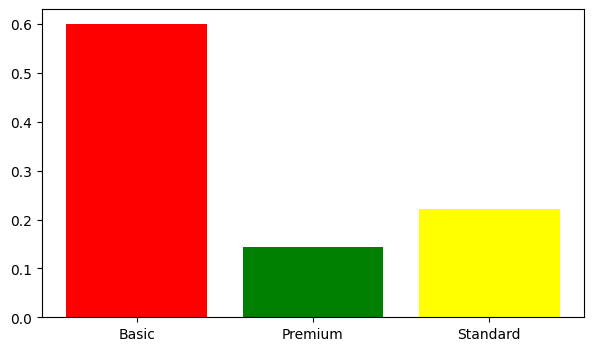

In [ ]:
from matplotlib import colors
churn_plan = df_visuals.groupby('plan_type')['churn_flag'].mean()
colors = ['red','green', 'yellow']

plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)
plt.show()

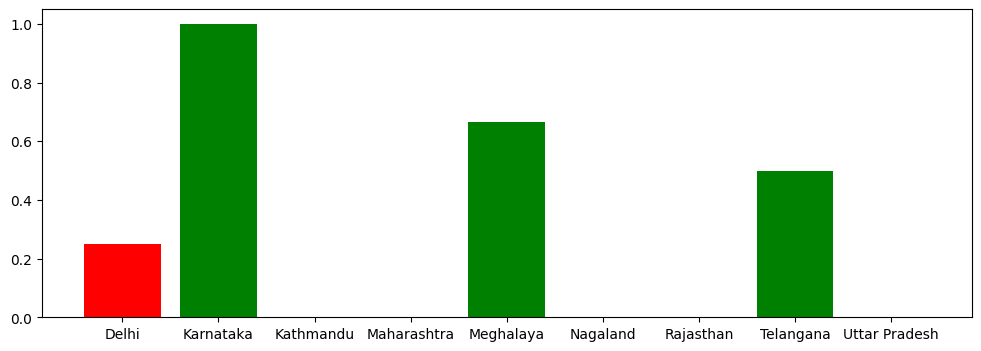

In [ ]:
from matplotlib import colors
churn_plan = df_visuals.groupby('state')['churn_flag'].mean()
colors = ['red','green', 'yellow']

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)
plt.show()

In [ ]:
df_visuals.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'churn_risk', 'cancellation_month'],
      dtype='object')

In [ ]:
#incorrect way to encoding
df_encoded = df_visuals[['plan_type', 'contract_type','churn_score', 'churn_flag','churn_risk', 'escalations']].copy()

categorical_cols = ['plan_type', 'contract_type', 'churn_risk']
for col in categorical_cols:
  df_encoded[col] = df_encoded[col].astype('category').cat.codes

<Axes: >

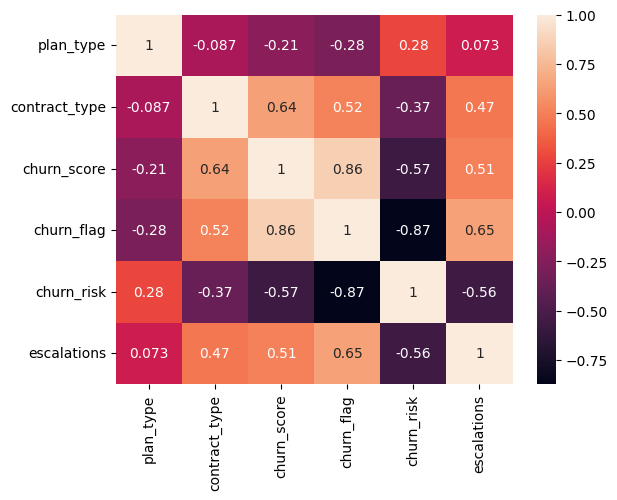

In [ ]:
sns.heatmap(df_encoded.corr(), annot=True)

In [ ]:
df_visuals['plan_type'].nunique()

3

In [ ]:
#correct way to encoding
df_encoded = df_visuals[['plan_type', 'contract_type','churn_score', 'churn_flag','churn_risk', 'escalations']].copy()

order_mappings ={
                 'plan_type' : ['Basic', 'Standard','Premium'],
                 'contract_type' : ['Monthly', 'Annual'],
                 'churn_risk' : ['low', 'med', 'high']
}

for col, categories in order_mappings.items():
  df_encoded[col] = pd.Categorical(df_encoded[col], categories=categories, ordered=True).codes

<Axes: >

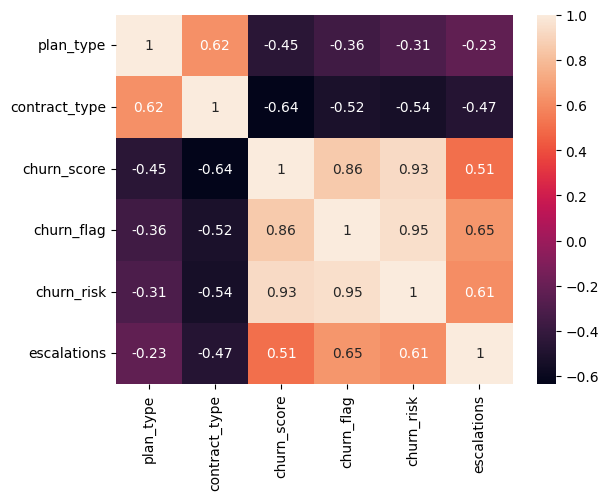

In [ ]:
sns.heatmap(df_encoded.corr(), annot=True)

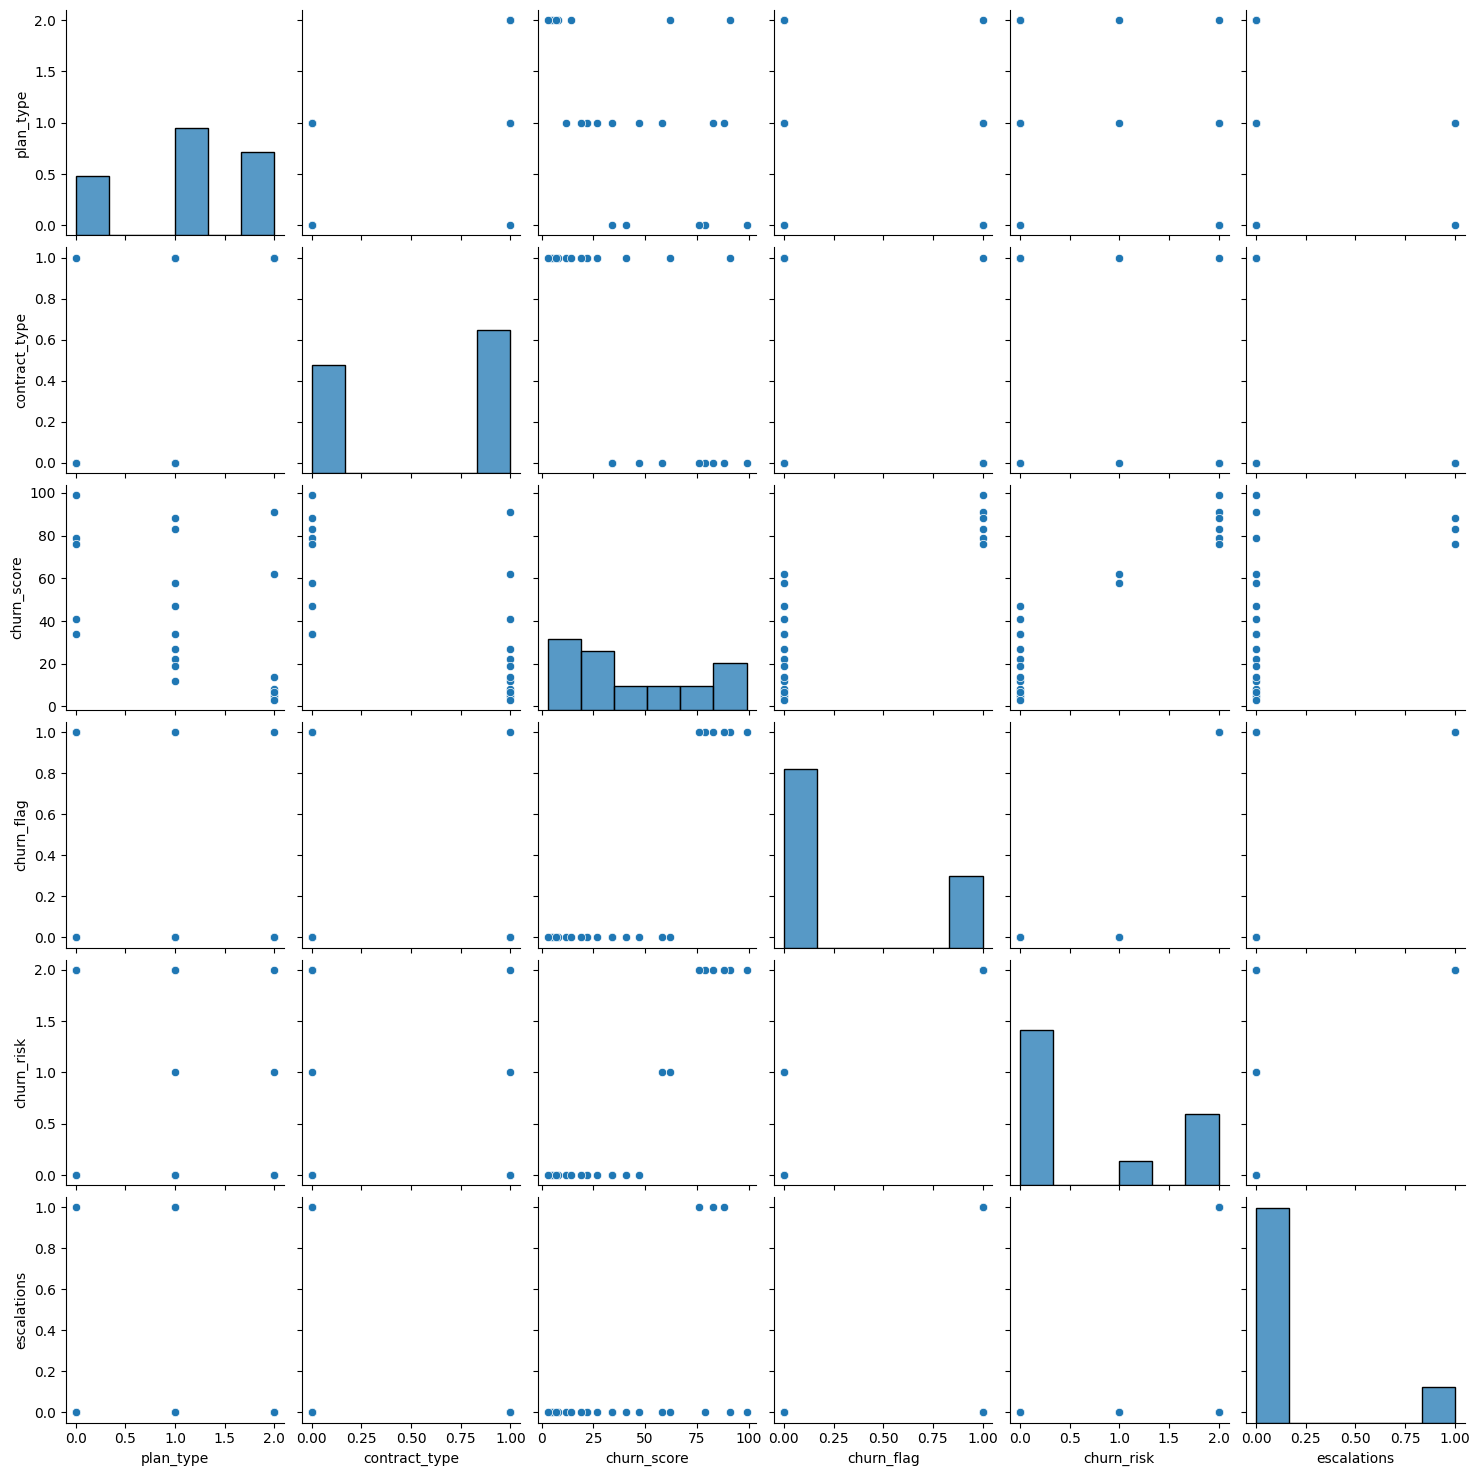

In [ ]:
sns.pairplot(df_encoded)

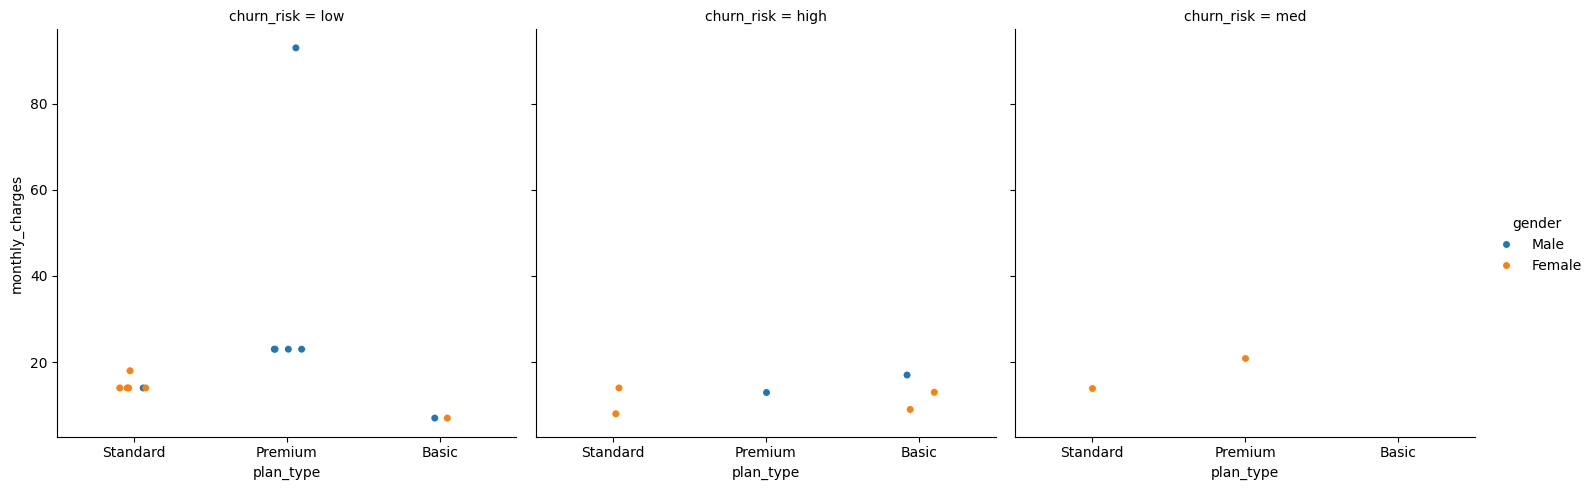

In [ ]:
sns.catplot(data=df_visuals,
            x ='plan_type',
            y ='monthly_charges',
            hue='gender',
            col='churn_risk'

)

In [ ]:
pd.pivot_table(
    df_visuals,
    values ='churn_flag',
    index = 'plan_type',
    aggfunc= 'mean'

)

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [ ]:
pd.pivot_table(
    df_visuals,
    index = 'plan_type',
    values =['monthly_charges','customerid','churn_flag'],

    aggfunc= {

            'monthly_charges' : 'sum',
            'customerid'  : 'nunique',
            'churn_flag' : 'mean'


    }

)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [ ]:
#working with SQL in python(Pandas)

In [ ]:
from sqlite3.dbapi2 import connect
#creating Database in SQL
conn = sqlite3.connect('test_database.sqlite')
#create table safely if it doesn't already exist
conn.execute("CREATE TABLE IF NOT EXISTS users (first_name TEXT, country TEXT , budget INTEGER)")
conn.commit()

In [ ]:
#Insert data
cursor = conn.cursor()

cursor.execute(
    """
        INSERT INTO users (first_name, country, budget) VALUES
            ('umair', 'pakistan', 50000),
            ('Waqas', 'pakistan', 60000),
            ('Asim', 'pakistan', 20000)
    """
)
conn.commit()
print("data inserted successfully")

data inserted successfully


In [ ]:
#Check Inserted data into table
conn = sqlite3.connect('test_database.sqlite')
query = "SELECT * FROM users"
df_results = pd.read_sql(query, conn)
df_results.head(3)

,first_name,country,budget
0,umair,pakistan,50000
1,Waqas,pakistan,60000
2,Asim,pakistan,20000


In [ ]:
#aggregation
import pandas as pd

query = """
    SELECT country, SUM(budget) AS total_budget
    FROM users
    GROUP BY country
"""
df_agg = pd.read_sql(query, conn)
df_agg

,country,total_budget
0,pakistan,130000


In [ ]:
conn.close()